In [22]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import os

In [23]:
img_size = (150, 150)
batch_size = 32

In [24]:
train_ds = keras.utils.image_dataset_from_directory(
    '/Users/abubakartamboli/Downloads/Pneumonia X Ray/chest_xray/train',
    image_size=img_size,
    batch_size=batch_size,
    color_mode="grayscale",
    label_mode="binary"
)


Found 4295 files belonging to 2 classes.


In [25]:
val_ds = keras.utils.image_dataset_from_directory(
    '/Users/abubakartamboli/Downloads/Pneumonia X Ray/chest_xray/val',
    image_size=img_size,
    batch_size=batch_size,
    color_mode="grayscale",
    label_mode="binary"
)

Found 16 files belonging to 2 classes.


In [26]:
test_ds = keras.utils.image_dataset_from_directory(
    '/Users/abubakartamboli/Downloads/Pneumonia X Ray/chest_xray/test',
    image_size=img_size,
    batch_size=batch_size,
    color_mode="grayscale",
    label_mode="binary"
)

Found 624 files belonging to 2 classes.


In [27]:
print("Classes:", train_ds.class_names)


Classes: ['NORMAL', 'PNEUMONIA']


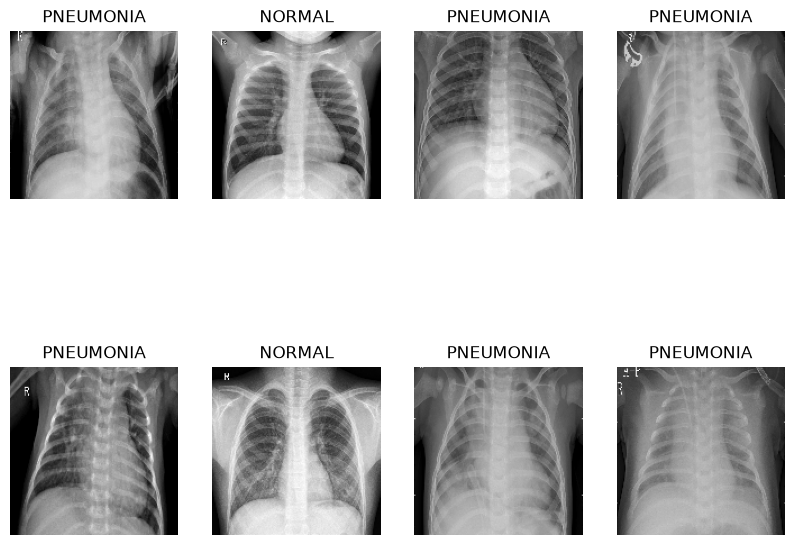

In [28]:
images, labels = next(iter(train_ds))
plt.figure(figsize=(10, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    # Display image
    plt.imshow(images[i].numpy().squeeze(), cmap='gray')

    # Display class name
    label = int(labels[i].numpy()[0])
    plt.title(train_ds.class_names[label])

    plt.axis('off')

plt.show()

In [29]:
class_names = train_ds.class_names

print(class_names)

['NORMAL', 'PNEUMONIA']


In [30]:
# Normalize pixel values
normalization = layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization(x), y)
)

test_ds = test_ds.map(
    lambda x, y: (normalization(x), y)
)

In [31]:
# Create CNN model
model = keras.Sequential([

    # First convolution layer
    layers.Conv2D(
        32, (3, 3),
        activation='relu',
        input_shape=(150, 150, 1)
    ),

    # First pooling layer
    layers.MaxPooling2D((2, 2)),

    # Second convolution layer
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Second pooling layer
    layers.MaxPooling2D((2, 2)),

    # Third convolution layer
    layers.Conv2D(128, (3, 3), activation='relu'),

    # Third pooling layer
    layers.MaxPooling2D((2, 2)),

    # Flatten feature maps
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Output layer
    layers.Dense(1, activation='sigmoid')
])

In [32]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 148, 148, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,827,905 (18.42 MB)

 Trainable params: 4,827,905 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [33]:
history = model.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds
)

Epoch 1/5
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 142ms/step - accuracy: 0.8817 - loss: 0.2626 - val_accuracy: 0.8750 - val_loss: 0.2764
Epoch 2/5
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 144ms/step - accuracy: 0.9625 - loss: 0.1107 - val_accuracy: 0.8750 - val_loss: 0.2672
Epoch 3/5
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 147ms/step - accuracy: 0.9693 - loss: 0.0887 - val_accuracy: 0.9375 - val_loss: 0.1720
Epoch 4/5
135/135 ━━━━━━━━━━━━━━━━━━━━ 20s 150ms/step - accuracy: 0.9776 - loss: 0.0593 - val_accuracy: 0.8750 - val_loss: 0.2017
Epoch 5/5
135/135 ━━━━━━━━━━━━━━━━━━━━ 21s 155ms/step - accuracy: 0.9793 - loss: 0.0548 - val_accuracy: 0.8750 - val_loss: 0.3607


In [34]:
loss, accuracy = model.evaluate(test_ds)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.7340 - loss: 1.5871 
Test Loss: 1.5871033668518066
Test Accuracy: 0.7339743375778198


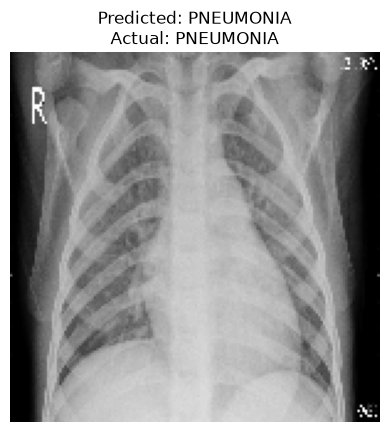

Predicted Class: PNEUMONIA
Actual Class: PNEUMONIA


In [37]:
images, labels = next(iter(test_ds))
# Select an image
index = 0

# Predict image
prediction = model.predict(
    images[index:index+1],
    verbose=0
)

# Convert prediction to class
predicted_class = 1 if prediction[0][0] >= 0.5 else 0

# Get actual class
actual_class = int(labels[index].numpy()[0])

# Display image
plt.imshow(images[index].numpy().squeeze(), cmap='gray')

plt.title(
    "Predicted: " + class_names[predicted_class] +
    "\nActual: " + class_names[actual_class]
)

plt.axis('off')
plt.show()

print("Predicted Class:",class_names[predicted_class])
print("Actual Class:", class_names[actual_class])